In [3]:
#Importing Packages
import pandas as pd
import numpy as np
import seaborn as sns
import plotly.express as px
import matplotlib.pyplot as plt

In [4]:
import glob
import kagglehub
import pandas as pd

path = kagglehub.dataset_download("pavansubhasht/ibm-hr-analytics-attrition-dataset")
df = pd.read_csv(glob.glob(f"{path}/*.csv")[0])
df.head()

Using Colab cache for faster access to the 'ibm-hr-analytics-attrition-dataset' dataset.


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


### Previewing the Data

In [5]:
df.head().T

,0,1,2,3,4
Age,41,49,37,33,27
Attrition,Yes,No,Yes,No,No
BusinessTravel,Travel_Rarely,Travel_Frequently,Travel_Rarely,Travel_Frequently,Travel_Rarely
DailyRate,1102,279,1373,1392,591
Department,Sales,Research & Development,Research & Development,Research & Development,Research & Development
DistanceFromHome,1,8,2,3,2
Education,2,1,2,4,1
EducationField,Life Sciences,Life Sciences,Other,Life Sciences,Medical
EmployeeCount,1,1,1,1,1
EmployeeNumber,1,2,4,5,7


In [6]:
df.shape

(1470, 35)

In [7]:
df.info

<bound method DataFrame.info of       Age Attrition     BusinessTravel  DailyRate              Department  \
0      41       Yes      Travel_Rarely       1102                   Sales   
1      49        No  Travel_Frequently        279  Research & Development   
2      37       Yes      Travel_Rarely       1373  Research & Development   
3      33        No  Travel_Frequently       1392  Research & Development   
4      27        No      Travel_Rarely        591  Research & Development   
...   ...       ...                ...        ...                     ...   
1465   36        No  Travel_Frequently        884  Research & Development   
1466   39        No      Travel_Rarely        613  Research & Development   
1467   27        No      Travel_Rarely        155  Research & Development   
1468   49        No  Travel_Frequently       1023                   Sales   
1469   34        No      Travel_Rarely        628  Research & Development   

      DistanceFromHome  Education EducationField  EmployeeCount  \
0                    1          2  Life Sciences              1   
1                    8          1  Life Sciences              1   
2                    2          2          Other              1   
3                    3          4  Life Sciences              1   
4                    2          1        Medical              1   
...                ...        ...            ...            ...   
1465                23          2        Medical              1   
1466                 6          1        Medical              1   
1467                 4          3  Life Sciences              1   
1468                 2          3        Medical              1   
1469                 8          3        Medical              1   

      EmployeeNumber  ...  RelationshipSatisfaction StandardHours  \
0                  1  ...                         1            80   
1                  2  ...                         4            80   
2                  4  ...                         2            80   
3                  5  ...                         3            80   
4                  7  ...                         4            80   
...              ...  ...                       ...           ...   
1465            2061  ...                         3            80   
1466            2062  ...                         1            80   
1467            2064  ...                         2            80   
1468            2065  ...                         4            80   
1469            2068  ...                         1            80   

      StockOptionLevel  TotalWorkingYears  TrainingTimesLastYear  \
0                    0                  8                      0   
1                    1                 10                      3   
2                    0                  7                      3   
3                    0                  8                      3   
4                    1                  6                      3   
...                ...                ...                    ...   
1465                 1                 17                      3   
1466                 1                  9                      5   
1467                 1                  6                      0   
1468                 0                 17                      3   
1469                 0                  6                      3   

     WorkLifeBalance  YearsAtCompany YearsInCurrentRole  \
0                  1               6                  4   
1                  3              10                  7   
2                  3               0                  0   
3                  3               8                  7   
4                  3               2                  2   
...              ...             ...                ...   
1465               3               5                  2   
1466               3               7                  7   
1467               3               6                  2   
14

In [8]:
df.dtypes

,0
Age,int64
Attrition,object
BusinessTravel,object
DailyRate,int64
Department,object
DistanceFromHome,int64
Education,int64
EducationField,object
EmployeeCount,int64
EmployeeNumber,int64


In [9]:
numerical_columns = df.select_dtypes(include=['number']).columns.tolist()
cat_col = df.select_dtypes(exclude=['number']).columns.tolist()

print("Numerical columns:", numerical_columns)

print("Categorical columns:", cat_col)

Numerical columns: ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']
Categorical columns: ['Attrition', 'BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'Over18', 'OverTime']


In [10]:
df.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


In [11]:
#Printing all the data types and their unique values
for column in df.columns:
    if df[column].dtype == object:
        print(f"{column}: {df[column].unique()}")
        print(df[column].value_counts())
        print('__________________________________________________________')

Attrition: ['Yes' 'No']
Attrition
No     1233
Yes     237
Name: count, dtype: int64
__________________________________________________________
BusinessTravel: ['Travel_Rarely' 'Travel_Frequently' 'Non-Travel']
BusinessTravel
Travel_Rarely        1043
Travel_Frequently     277
Non-Travel            150
Name: count, dtype: int64
__________________________________________________________
Department: ['Sales' 'Research & Development' 'Human Resources']
Department
Research & Development    961
Sales                     446
Human Resources            63
Name: count, dtype: int64
__________________________________________________________
EducationField: ['Life Sciences' 'Other' 'Medical' 'Marketing' 'Technical Degree'
 'Human Resources']
EducationField
Life Sciences       606
Medical             464
Marketing           159
Technical Degree    132
Other                82
Human Resources      27
Name: count, dtype: int64
__________________________________________________________
Gender: ['Femal

### Data Cleaning

In [12]:
#Getting a count of the empty values for each column
df.isna().sum()

,0
Age,0
Attrition,0
BusinessTravel,0
DailyRate,0
Department,0
DistanceFromHome,0
Education,0
EducationField,0
EmployeeCount,0
EmployeeNumber,0


In [13]:
#Check for duplicates in the dataset
df.duplicated().sum()

np.int64(0)

In [14]:
#Deleting unnecessary rows
df = df.drop('Over18', axis = 1 )
df = df.drop('EmployeeNumber', axis = 1 )
df = df.drop('EmployeeCount', axis = 1 )
df = df.drop('StandardHours', axis = 1 )

In [15]:
df.shape

(1470, 31)

### Exploratory Data Analysis

### 1.Univariate Analysis

In [16]:
#Get a count of the number of employees that stayed and left the company
df['Attrition'].value_counts()

,count
Attrition,
No,1233
Yes,237


In [17]:
color_map = {
    'Yes': 'red',
    'No': 'blue'}
# Plotly histogram with custom colors
fig = px.histogram(df, x='Attrition', color='Attrition', width=600, height=400,
                   color_discrete_map=color_map, title='Attrition Histogram')
fig.show()
#sns.countplot(x='Attrition',hue='Attrition', data=df)

In [18]:
# List of columns to visualize
columns_to_visualize = ['YearsAtCompany', 'MonthlyIncome', 'JobSatisfaction', 'Department']

# Create histograms using a for loop
for column in columns_to_visualize:
    fig = px.histogram(df, x=column, nbins=10, title=f'Distribution of {column}')
    fig.update_layout(bargap=0.2)
    fig.show()

### Bivariate Analysis

In [19]:
#Number of employees who left by Age.
color_map = {
    'Yes': 'red',
    'No': 'blue'}
fig = px.histogram(df, x='Age',color_discrete_map=color_map, color='Attrition',title='Attrition Histogram by Age')
fig.update_layout(bargap=0.2)
fig.show()

In [20]:
#Number of employees who left by Monthly Inocme.
color_map = {
    'Yes': 'red',
    'No': 'blue'}
fig = px.histogram(df, x='MonthlyIncome',color_discrete_map=color_map, color='Attrition',title='Attrition Histogram by Monthly Income')
fig.update_layout(bargap=0.2)
fig.show()

In [21]:
#Number of employees who left by Over Time.
color_map = {
    'Yes': 'red',
    'No': 'blue'}
fig = px.histogram(df, x='OverTime',color_discrete_map=color_map, color='Attrition',title='Attrition Histogram by Over Time')
fig.update_layout(bargap=0.2)
fig.show()

In [22]:
#Number of employees who left by Job Satisfaction.
color_map = {
    'Yes': 'red',
    'No': 'blue'}
fig = px.histogram(df, x='JobSatisfaction',color_discrete_map=color_map, color='Attrition',title='Attrition Histogram by Job Satisfaction')
fig.update_layout(bargap=0.2)
fig.show()

In [23]:
#Number of employees who left by Departments.
color_map = {
    'Yes': 'red',
    'No': 'blue'}
fig = px.histogram(df, x='Department',color_discrete_map=color_map, color='Attrition',title='Attrition Histogram by Department')
fig.update_layout(bargap=0.2)
fig.show()

In [24]:
#Number of employees who left by Gender.
color_map = {
    'Yes': 'red',
    'No': 'blue'}
fig = px.histogram(df, x='Gender',color_discrete_map=color_map, color='Attrition',title='Attrition Histogram by Gender')
fig.update_layout(bargap=0.2)
fig.show()

In [25]:
fig = px.scatter(df, x='YearsAtCompany', y='MonthlyIncome',
                 title='Scatter Plot of Years at Company vs. Monthly Income',
                 labels={'YearsAtCompany': 'Years at Company', 'MonthlyIncome': 'Monthly Income'},
                 trendline="ols")  # Adding a trendline
fig.show()

In [26]:
avg_income_by_jobrole = df.groupby('JobRole')['MonthlyIncome'].mean().reset_index()

# Create bar plot
fig = px.bar(avg_income_by_jobrole, x='JobRole', y='MonthlyIncome',
             title='Average Monthly Income by Job Role',
             labels={'JobRole': 'Job Role', 'MonthlyIncome': 'Average Monthly Income'})
fig.show()

### Multivariate Analysis

In [27]:
non_numeric_columns = df.select_dtypes(exclude=['number']).columns

# Exclusion non-numeric columns from correlation calculation
df_numeric = df.drop(columns=non_numeric_columns)
df_numeric.corr()

,Age,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,MonthlyIncome,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
Age,1.000000,0.010661,-0.001686,0.208034,0.010146,0.024287,0.029820,0.509604,-0.004892,0.497855,...,0.001904,0.053535,0.037510,0.680381,-0.019621,-0.021490,0.311309,0.212901,0.216513,0.202089
DailyRate,0.010661,1.000000,-0.004985,-0.016806,0.018355,0.023381,0.046135,0.002966,0.030571,0.007707,...,0.000473,0.007846,0.042143,0.014515,0.002453,-0.037848,-0.034055,0.009932,-0.033229,-0.026363
DistanceFromHome,-0.001686,-0.004985,1.000000,0.021042,-0.016075,0.031131,0.008783,0.005303,-0.003669,-0.017014,...,0.027110,0.006557,0.044872,0.004628,-0.036942,-0.026556,0.009508,0.018845,0.010029,0.014406
Education,0.208034,-0.016806,0.021042,1.000000,-0.027128,0.016775,0.042438,0.101589,-0.011296,0.094961,...,-0.024539,-0.009118,0.018422,0.148280,-0.025100,0.009819,0.069114,0.060236,0.054254,0.069065
EnvironmentSatisfaction,0.010146,0.018355,-0.016075,-0.027128,1.000000,-0.049857,-0.008278,0.001212,-0.006784,-0.006259,...,-0.029548,0.007665,0.003432,-0.002693,-0.019359,0.027627,0.001458,0.018007,0.016194,-0.004999
HourlyRate,0.024287,0.023381,0.031131,0.016775,-0.049857,1.000000,0.042861,-0.027853,-0.071335,-0.015794,...,-0.002172,0.001330,0.050263,-0.002334,-0.008548,-0.004607,-0.019582,-0.024106,-0.026716,-0.020123
JobInvolvement,0.029820,0.046135,0.008783,0.042438,-0.008278,0.042861,1.000000,-0.012630,-0.021476,-0.015271,...,-0.029071,0.034297,0.021523,-0.005533,-0.015338,-0.014617,-0.021355,0.008717,-0.024184,0.025976
JobLevel,0.509604,0.002966,0.005303,0.101589,0.001212,-0.027853,-0.012630,1.000000,-0.001944,0.950300,...,-0.021222,0.021642,0.013984,0.782208,-0.018191,0.037818,0.534739,0.389447,0.353885,0.375281
JobSatisfaction,-0.004892,0.030571,-0.003669,-0.011296,-0.006784,-0.071335,-0.021476,-0.001944,1.000000,-0.007157,...,0.002297,-0.012454,0.010690,-0.020185,-0.005779,-0.019459,-0.003803,-0.002305,-0.018214,-0.027656
MonthlyIncome,0.497855,0.007707,-0.017014,0.094961,-0.006259,-0.015794,-0.015271,0.950300,-0.007157,1.000000,...,-0.017120,0.025873,0.005408,0.772893,-0.021736,0.030683,0.514285,0.363818,0.344978,0.344079


<Axes: >

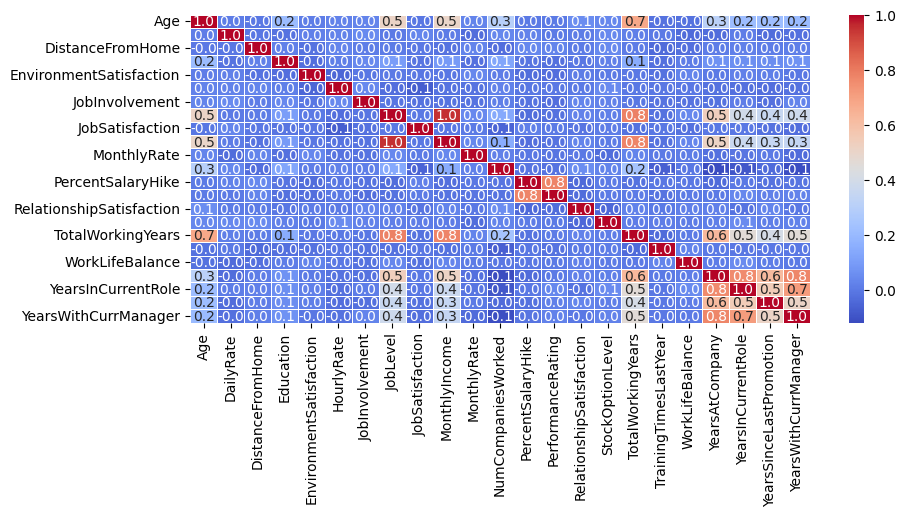

In [28]:
plt.figure(figsize=(10,4))
sns.heatmap(df_numeric.corr(),annot=True,cmap='coolwarm',linewidth=0.5,fmt='0.1f')

In [29]:
df.columns

Index(['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department',
       'DistanceFromHome', 'Education', 'EducationField',
       'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement',
       'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus',
       'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'OverTime',
       'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction',
       'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear',
       'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole',
       'YearsSinceLastPromotion', 'YearsWithCurrManager'],
      dtype='object')

### Preprocessing the Data

In [30]:
df.T

,0,1,2,3,4,5,6,7,8,9,...,1460,1461,1462,1463,1464,1465,1466,1467,1468,1469
Age,41,49,37,33,27,32,59,30,38,36,...,29,50,39,31,26,36,39,27,49,34
Attrition,Yes,No,Yes,No,No,No,No,No,No,No,...,No,Yes,No,No,No,No,No,No,No,No
BusinessTravel,Travel_Rarely,Travel_Frequently,Travel_Rarely,Travel_Frequently,Travel_Rarely,Travel_Frequently,Travel_Rarely,Travel_Rarely,Travel_Frequently,Travel_Rarely,...,Travel_Rarely,Travel_Rarely,Travel_Rarely,Non-Travel,Travel_Rarely,Travel_Frequently,Travel_Rarely,Travel_Rarely,Travel_Frequently,Travel_Rarely
DailyRate,1102,279,1373,1392,591,1005,1324,1358,216,1299,...,468,410,722,325,1167,884,613,155,1023,628
Department,Sales,Research & Development,Research & Development,Research & Development,Research & Development,Research & Development,Research & Development,Research & Development,Research & Development,Research & Development,...,Research & Development,Sales,Sales,Research & Development,Sales,Research & Development,Research & Development,Research & Development,Sales,Research & Development
DistanceFromHome,1,8,2,3,2,2,3,24,23,27,...,28,28,24,5,5,23,6,4,2,8
Education,2,1,2,4,1,2,3,1,3,3,...,4,3,1,3,3,2,1,3,3,3
EducationField,Life Sciences,Life Sciences,Other,Life Sciences,Medical,Life Sciences,Medical,Life Sciences,Life Sciences,Medical,...,Medical,Marketing,Marketing,Medical,Other,Medical,Medical,Life Sciences,Medical,Medical
EnvironmentSatisfaction,2,3,4,4,1,4,3,4,4,3,...,4,4,2,2,4,3,4,2,4,2
Gender,Female,Male,Male,Female,Male,Male,Female,Male,Male,Male,...,Female,Male,Female,Male,Female,Male,Male,Male,Male,Male


In [31]:
#Transforming non-numerical into numerical col
from sklearn.preprocessing import LabelEncoder

for column in df.columns:
    if df[column].dtype == np.number:
        continue
    df[column] = LabelEncoder().fit_transform(df[column])

In [32]:
df.T

,0,1,2,3,4,5,6,7,8,9,...,1460,1461,1462,1463,1464,1465,1466,1467,1468,1469
Age,23,31,19,15,9,14,41,12,20,18,...,11,32,21,13,8,18,21,9,31,16
Attrition,1,0,1,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
BusinessTravel,2,1,2,1,2,1,2,2,1,2,...,2,2,2,0,2,1,2,2,1,2
DailyRate,624,113,805,820,312,572,770,794,78,751,...,228,191,403,143,663,494,327,39,579,336
Department,2,1,1,1,1,1,1,1,1,1,...,1,2,2,1,2,1,1,1,2,1
DistanceFromHome,0,7,1,2,1,1,2,23,22,26,...,27,27,23,4,4,22,5,3,1,7
Education,1,0,1,3,0,1,2,0,2,2,...,3,2,0,2,2,1,0,2,2,2
EducationField,1,1,4,1,3,1,3,1,1,3,...,3,2,2,3,4,3,3,1,3,3
EnvironmentSatisfaction,1,2,3,3,0,3,2,3,3,2,...,3,3,1,1,3,2,3,1,3,1
Gender,0,1,1,0,1,1,0,1,1,1,...,0,1,0,1,0,1,1,1,1,1


In [33]:
df['Age_Years'] = df['Age']

In [34]:
df = df.drop('Age',axis=1)

In [35]:
df

,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,HourlyRate,...,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Age_Years
0,1,2,624,2,0,1,1,1,0,64,...,0,0,8,0,0,6,4,0,5,23
1,0,1,113,1,7,0,1,2,1,31,...,3,1,10,3,2,10,7,1,7,31
2,1,2,805,1,1,1,4,3,1,62,...,1,0,7,3,2,0,0,0,0,19
3,0,1,820,1,2,3,1,3,0,26,...,2,0,8,3,2,8,7,3,0,15
4,0,2,312,1,1,0,3,0,1,10,...,3,1,6,3,2,2,2,2,2,9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1465,0,1,494,1,22,1,3,2,1,11,...,2,1,17,3,2,5,2,0,3,18
1466,0,2,327,1,5,0,3,3,1,12,...,0,1,9,5,2,7,7,1,7,21
1467,0,2,39,1,3,2,1,1,1,57,...,1,1,6,0,2,6,2,0,3,9
1468,0,1,579,2,1,2,3,3,1,33,...,3,0,17,3,1,9,6,0,8,31


### Building the Model

In [36]:
#Split the dependent and independent features
X=df.drop(['Attrition'],axis=1)

Y=df['Attrition']

In [37]:
# Split

from sklearn.model_selection import train_test_split

x_train , x_test , y_train, y_test = train_test_split(X,Y, test_size= 0.2, random_state= 42)

In [38]:
x_train.shape

(1176, 30)

In [39]:
x_test.shape

(294, 30)

In [40]:
y_train.shape

(1176,)

In [41]:
y_test.shape

(294,)

In [42]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Create a Decision Tree classifier instance
decision_tree = DecisionTreeClassifier(random_state=42)

# Fit the model
decision_tree.fit(x_train, y_train)

# Predict on the test set
y_pred_dt = decision_tree.predict(x_test)

In [43]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Create a Logistic Regression classifier instance
logistic_regression = LogisticRegression(random_state=42)

# Fit the model
logistic_regression.fit(x_train, y_train)

# Predict on the test set
y_pred_lr = logistic_regression.predict(x_test)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning:

lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression



In [44]:
from sklearn.ensemble import RandomForestClassifier
# Create a Random Forest classifier instance
random_forest = RandomForestClassifier(random_state=42)

# Fit the model
random_forest.fit(x_train, y_train)

# Predict on the test set
y_pred_rf = random_forest.predict(x_test)

### Evaluation

In [45]:
# Calculate accuracy
accuracy_dt = accuracy_score(y_test, y_pred_dt)
print(f"Decision Tree Accuracy: {accuracy_dt}")

# Calculate accuracy
accuracy_rf = accuracy_score(y_test, y_pred_rf)
print(f"Random Forest Accuracy: {accuracy_rf}")

if accuracy_dt > accuracy_rf:
    better_classifier = "Decision Tree"
elif accuracy_rf > accuracy_dt:
    better_classifier = "Random Forest"
else:
    better_classifier = "Both classifiers perform equally well"

print(f"The better classifier based on accuracy is {better_classifier}")

Decision Tree Accuracy: 0.7959183673469388
Random Forest Accuracy: 0.8707482993197279
The better classifier based on accuracy is Random Forest


In [46]:
#Confusion Matrix for further evaluation
from sklearn import metrics

In [47]:
cm = metrics.confusion_matrix(y_test, y_pred_rf)
print(cm)

[[252   3]
 [ 35   4]]


Text(0.5, 1.0, 'Accuracy Score: 0.8707482993197279')

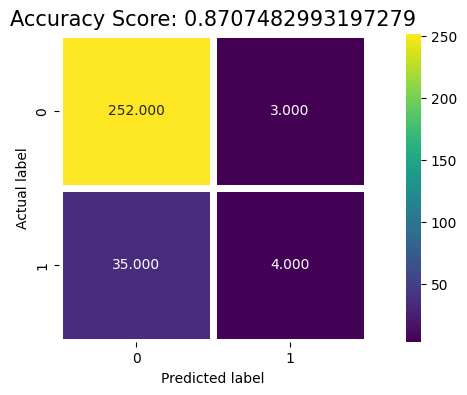

In [48]:
plt.figure(figsize=(10, 4))
sns.heatmap(cm, annot=True, fmt=".3f", linewidths=5, square=True, cmap='viridis')
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
all_sample_title = 'Accuracy Score: {0}'.format(accuracy_rf)
plt.title(all_sample_title, size=15)

In [49]:
256/294 #Accuracy score is the same.

0.8707482993197279

In [50]:
import plotly.graph_objects as go
# Data for the bar plot
models = ['Decision Tree', 'Random Forest']
accuracies = [accuracy_dt, accuracy_rf]

# Create a bar plot using Plotly
fig = go.Figure(data=[go.Bar(x=models, y=accuracies, text=accuracies, textposition='auto', marker_color=['blue', 'green'])])

# Customize layout
fig.update_layout(title='Accuracy of Decision Tree vs Random Forest Classifiers',
                  xaxis_title='Models',
                  yaxis_title='Accuracy',
                  template='plotly_white',
                  width=600,
                  height=400)

# Show the plot
fig.show()

In [51]:
x_test.columns

Index(['BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome',
       'Education', 'EducationField', 'EnvironmentSatisfaction', 'Gender',
       'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole',
       'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate',
       'NumCompaniesWorked', 'OverTime', 'PercentSalaryHike',
       'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel',
       'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance',
       'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion',
       'YearsWithCurrManager', 'Age_Years'],
      dtype='object')

In [52]:
df['YearsWithCurrManager'].min()

0

In [53]:
df['WorkLifeBalance'].unique()

array([0, 2, 1, 3])

In [54]:
df['JobInvolvement'].unique()

array([2, 1, 3, 0])

In [55]:
#Printing all the data types and their unique values
for column in df.columns:
    if df[column].dtype == object:
        print(f"{column}: {df[column].unique()}")
        print(df[column].value_counts())
        print('__________________________________________________________')

In [56]:
df.head(30)

,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,HourlyRate,...,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Age_Years
0,1,2,624,2,0,1,1,1,0,64,...,0,0,8,0,0,6,4,0,5,23
1,0,1,113,1,7,0,1,2,1,31,...,3,1,10,3,2,10,7,1,7,31
2,1,2,805,1,1,1,4,3,1,62,...,1,0,7,3,2,0,0,0,0,19
3,0,1,820,1,2,3,1,3,0,26,...,2,0,8,3,2,8,7,3,0,15
4,0,2,312,1,1,0,3,0,1,10,...,3,1,6,3,2,2,2,2,2,9
5,0,1,572,1,1,1,1,3,1,49,...,2,0,8,2,1,7,7,3,6,14
6,0,2,770,1,2,2,3,2,0,51,...,0,3,12,3,1,1,0,0,0,41
7,0,2,794,1,23,0,1,3,1,37,...,1,1,1,2,2,1,0,0,0,12
8,0,1,78,1,22,2,1,3,1,14,...,1,0,10,2,2,9,7,1,8,20
9,0,2,751,1,26,2,3,2,1,64,...,1,2,17,3,1,7,7,7,7,18


In [57]:
import sklearn
print(sklearn.__version__)

1.6.1


In [59]:
import joblib
from google.colab import files

joblib.dump(random_forest, "random_forest.pkl", compress=3)
files.download("random_forest.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>